<a href="https://colab.research.google.com/github/yalini154/1/blob/main/image_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout, Conv2D, MaxPooling2D
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.utils import to_categorical, load_img, img_to_array
from tensorflow.keras.optimizers import SGD
from numpy import argmax
import numpy as np
import os
from PIL import Image

In [6]:
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/cifar10.tgz

!tar -xzf cifar10.tgz

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


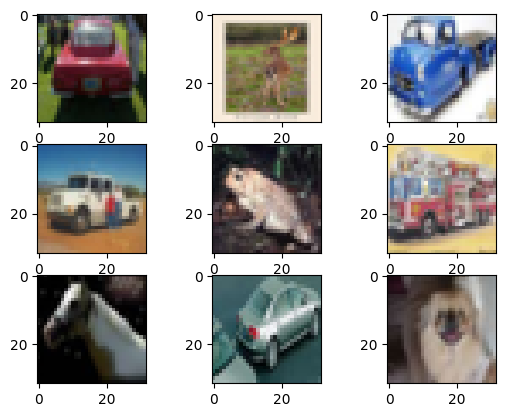

In [11]:
import matplotlib.pyplot as plt

def load_split(folder):
  class_names = sorted(os.listdir(folder))
  images, labels = [], []
  for label, class_name in enumerate(class_names):
    class_dir = os.path.join(folder, class_name)
    for filename in os.listdir(class_dir):
      img = Image.open(os.path.join(class_dir, filename)).convert('RGB')
      images.append(np.array(img))
      labels.append(label)
  x = np.array(images)
  y = np.array(labels).reshape(-1, 1)

  shuffle_order = np.random.permutation(len(x))
  return x[shuffle_order], y[shuffle_order], class_names

x_train, y_train, train_class_names = load_split('cifar10/train')
x_test, y_test, _ = load_split('cifar10/test')

print(train_class_names)

for i in range(9):
  plt.subplot(330 + 1 + i)
  plt.imshow(x_train[i])
plt.show()